# Phase 2: Pipeline Execution and Visual Diagnostics

Suwayhib word-level recitation error detection (binary classification).
Implements the Phase 1 strategy (`phase1_strategy/Phase1_Strategy_Report.pdf`):
build the table, split by reciter **first**, fit every transformer on
`X_train` only, produce the 8 diagnostic figures, and verify the output.

In [1]:
import sys, json
from pathlib import Path

# find the repository root, so src/ imports work from any folder
ROOT = Path.cwd()
while not (ROOT / "src").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("run this notebook from inside the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, cross_validate
from sklearn.metrics import (average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from src.build_dataset import build
from src.audit import compute_vif
from src.transformers import add_engineered_features
from src import pipeline_builder as pb

# where figures and processed data are saved
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

# save a figure at 300 DPI, then show it in the notebook
def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Load raw data and build the word-level table

In [2]:
# join the raw label and score files into one row per word
df = build()
df.to_csv(PROC / "word_table.csv", index=False)

n_recordings = df["recording_id"].nunique()
n_positive = df[pb.TARGET].sum()
positive_rate = df[pb.TARGET].mean()
print("raw table:", df.shape, "| recordings:", n_recordings,
      "| positives:", n_positive, f"({positive_rate:.2%})")
df.head()

raw table: (9086, 23) | recordings: 2000 | positives: 1400 (15.41%)


,recording_id,word_idx,reciter,surah,ayah,n_words,orig_duration_ms,new_duration_ms,stretch_rate,error_type,...,ref_frac,dtw_cost,width,dur_ratio,dur_z,cost_z,collapsed,log_dev,suspicion,is_error_word
0,0,0,Husary_64kbps,83,28,4,9560,7522,2.33,madd_shortening,...,0.158371,0.091950,144.0,1.677596,0.642329,-1.230316,0.0,0.517958,0.642329,0
1,0,1,Husary_64kbps,83,28,4,9560,7522,2.33,madd_shortening,...,0.282460,0.173373,177.0,1.109743,-2.457305,-0.118666,0.0,0.105029,0.000000,0
2,0,2,Husary_64kbps,83,28,4,9560,7522,2.33,madd_shortening,...,0.070615,0.190757,55.0,1.413559,-0.642329,0.118666,0.0,0.346818,0.118666,0
3,0,3,Husary_64kbps,83,28,4,9560,7522,2.33,madd_shortening,...,0.517084,0.311591,168.0,0.589653,0.706653,1.768390,0.0,0.526527,2.475043,1
4,1,0,Abu_Bakr_Ash-Shaatree_128kbps,91,13,7,6295,7695,NaN,word_repetition,...,0.122727,0.289178,76.0,0.858889,-0.832421,-0.049844,0.0,0.150951,0.000000,0


## 2. Split first (by reciter), before any fitting

In [3]:
# split by reciter first, before anything is fitted
is_test = df[pb.GROUP].isin(pb.TEST_RECITERS)
train = df[~is_test].reset_index(drop=True)
test = df[is_test].reset_index(drop=True)

# separate the features from the target
X_train = train.drop(columns=[pb.TARGET])
y_train = train[pb.TARGET]
X_test = test.drop(columns=[pb.TARGET])
y_test = test[pb.TARGET]
g_train = train[pb.GROUP]

# no reciter or recording may appear on both sides
shared_reciters = set(train["reciter"]) & set(test["reciter"])
shared_recordings = set(train["recording_id"]) & set(test["recording_id"])
assert len(shared_reciters) == 0
assert len(shared_recordings) == 0

# one row per partition, to compare sizes and error rates
split_summary = pd.DataFrame(index=["train", "test"])
split_summary["rows"] = [len(train), len(test)]
split_summary["share"] = [len(train) / len(df), len(test) / len(df)]
split_summary["reciters"] = [train["reciter"].nunique(), test["reciter"].nunique()]
split_summary["recordings"] = [train["recording_id"].nunique(), test["recording_id"].nunique()]
split_summary["positive_rate"] = [y_train.mean(), y_test.mean()]
split_summary["error_words"] = [int(y_train.sum()), int(y_test.sum())]
split_summary["neg_per_pos"] = [(1 - y_train.mean()) / y_train.mean(),
                                (1 - y_test.mean()) / y_test.mean()]
split_summary.round(3)

,rows,share,reciters,recordings,positive_rate,error_words,neg_per_pos
train,6763,0.744,6,1470,0.149,1009,5.703
test,2323,0.256,2,530,0.168,391,4.941


## Figure 1.1: Missingness pattern heatmap

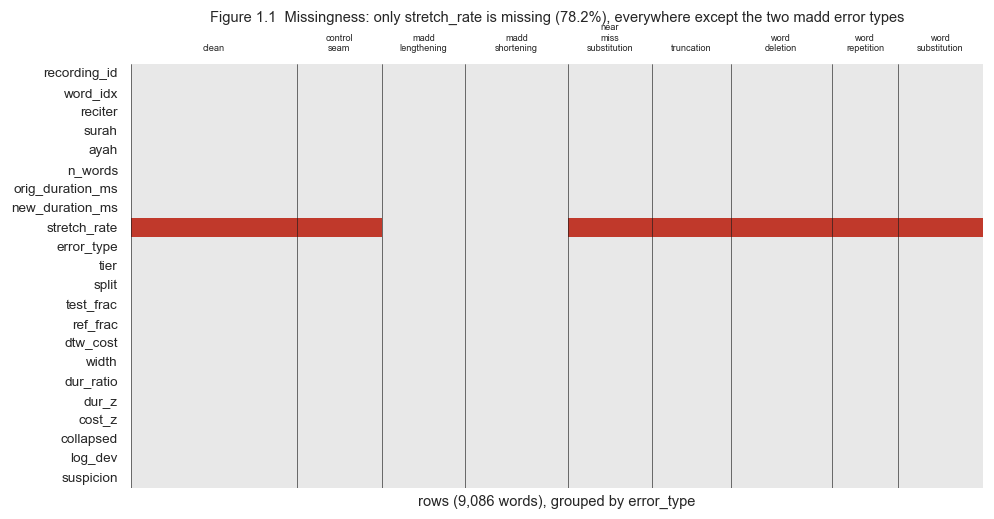

In [4]:
# group rows by error type so the missingness pattern is visible
df_sorted = df.sort_values(["error_type", "recording_id"]).reset_index(drop=True)
is_missing = df_sorted.drop(columns=[pb.TARGET]).isna()

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(is_missing.T, cbar=False, cmap=["#e8e8e8", "#c0392b"], ax=ax, xticklabels=False)

# draw a divider and a label at the start of each error type
for error_type in df_sorted["error_type"].unique():
    rows_of_type = df_sorted.index[df_sorted["error_type"] == error_type]
    first_row = rows_of_type[0]
    middle_row = np.mean(rows_of_type)
    label = error_type.replace("_", "\n")
    ax.axvline(first_row, color="k", lw=0.4)
    ax.text(middle_row, -0.6, label, ha="center", va="bottom", fontsize=6)

ax.set_xlabel("rows (9,086 words), grouped by error_type")
ax.set_title("Figure 1.1  Missingness: only stretch_rate is missing (78.2%), "
             "everywhere except the two madd error types", pad=28)
save(fig, "fig1_1_missingness_heatmap")

## Figure 1.2: Target distribution

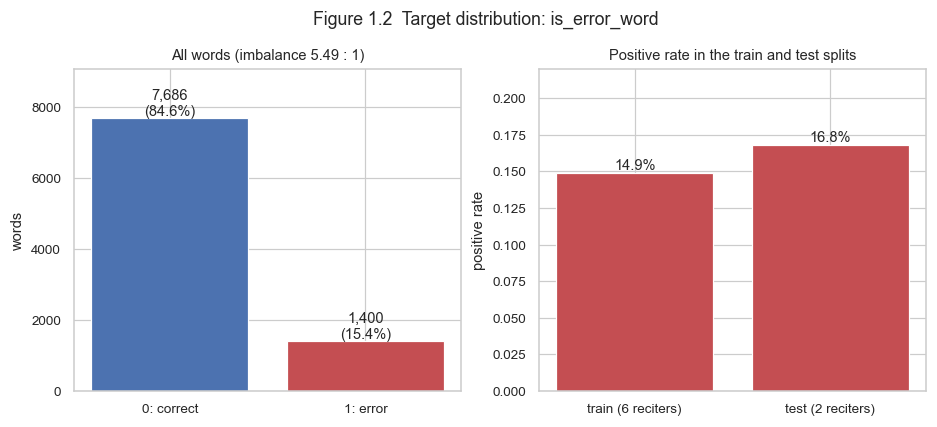

In [5]:
# class counts for the left panel
counts = df[pb.TARGET].value_counts().sort_index()
n_correct = counts[0]
n_error = counts[1]
imbalance_ratio = n_correct / n_error

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

left = axes[0]
bars = left.bar(["0: correct", "1: error"], counts.values, color=["#4c72b0", "#c44e52"])
for bar, count in zip(bars, counts.values):
    bar_center = bar.get_x() + bar.get_width() / 2
    share = count / len(df)
    left.text(bar_center, count, f"{count:,}\n({share:.1%})", ha="center", va="bottom")
left.set_ylim(0, counts.max() * 1.18)
left.set_title(f"All words (imbalance {imbalance_ratio:.2f} : 1)")
left.set_ylabel("words")

# error rate in each partition, for the right panel
right = axes[1]
split_names = ["train (6 reciters)", "test (2 reciters)"]
split_rates = [y_train.mean(), y_test.mean()]
right.bar(split_names, split_rates, color="#c44e52")
for position, rate in enumerate(split_rates):
    right.text(position, rate, f"{rate:.1%}", ha="center", va="bottom")
right.set_ylabel("positive rate")
right.set_ylim(0, 0.22)
right.set_title("Positive rate in the train and test splits")

fig.suptitle("Figure 1.2  Target distribution: is_error_word", y=1.02)
save(fig, "fig1_2_target_distribution")

## 3. Fit the preprocessor on `X_train` only

`build_preprocessor` = feature engineering → fixed column drops →
median impute → log1p (skewed positives) → IQR winsorize (k = 3, fences
from train) → StandardScaler.

In [6]:
# fit on X_train only; X_test is only transformed
pre = pb.build_preprocessor()
pre.fit(X_train)
Xt_train = pre.transform(X_train)
Xt_test = pre.transform(X_test)

print("train:", X_train.shape, "->", Xt_train.shape)
print("test: ", X_test.shape, "->", Xt_test.shape)
print("features:", list(Xt_train.columns))

# pull out the fitted steps to inspect them
column_step = pre.named_steps["columns"]
numeric_pipeline = column_step.named_transformers_["num"]
imputer = numeric_pipeline.named_steps["impute"]
log_step = numeric_pipeline.named_steps["log"]
capper = numeric_pipeline.named_steps["cap"]

# the capping fences learned from the training data
fences = pd.DataFrame({"lower": capper.lower_, "upper": capper.upper_})
fences.round(3)

train: (6763, 22) -> (6763, 9)
test:  (2323, 22) -> (2323, 9)
features: ['ref_frac', 'dtw_cost', 'width', 'dur_ratio', 'cost_z', 'log_dev', 'suspicion', 'n_words', 'rec_len_ratio']


,lower,upper
ref_frac,-0.403,0.813
dtw_cost,-0.245,0.902
width,1.526,7.440
dur_ratio,0.136,1.243
cost_z,-4.721,4.721
log_dev,-0.682,1.067
suspicion,-2.825,3.766
n_words,0.600,2.955
rec_len_ratio,0.548,1.339


## Figure 2.1: Outlier box plots before and after capping (training split)

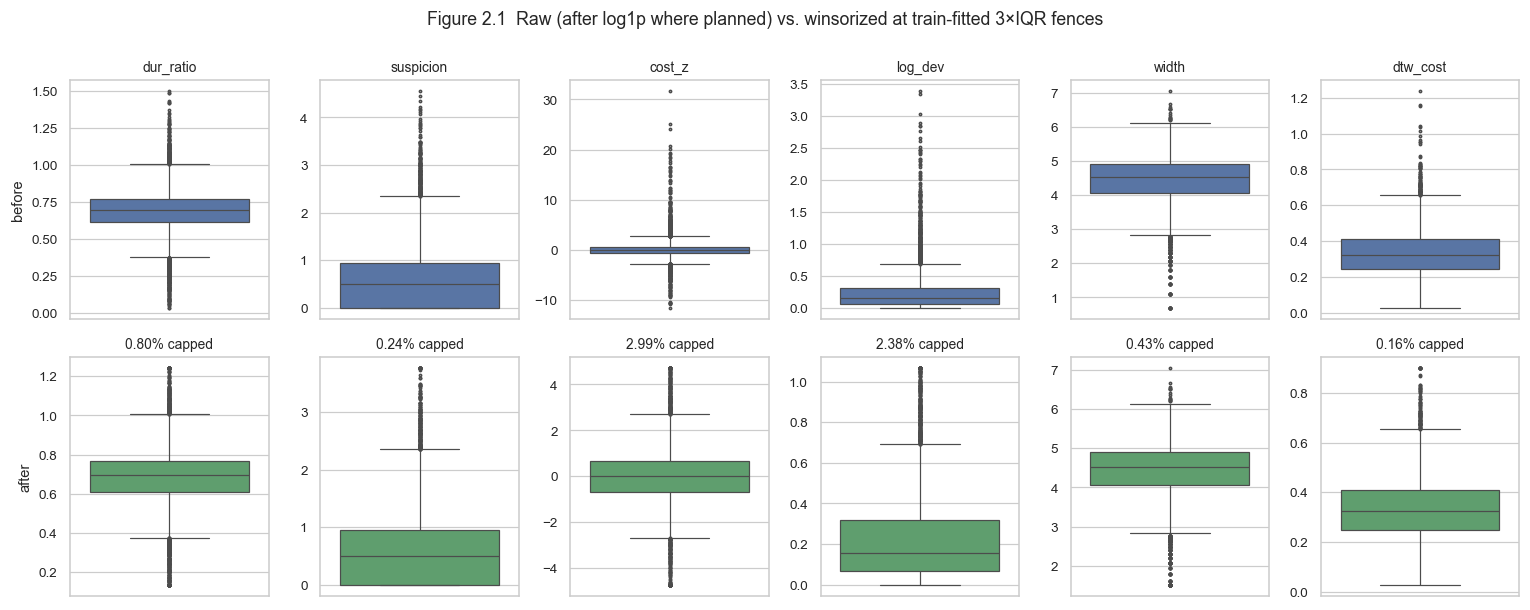

,lower,upper,capped_train_%
ref_frac,-0.402985,0.813286,0.00
dtw_cost,-0.244738,0.901857,0.16
width,1.525948,7.439770,0.43
dur_ratio,0.135530,1.242913,0.80
cost_z,-4.721435,4.721435,2.99
log_dev,-0.681695,1.067376,2.38
suspicion,-2.824635,3.766180,0.24
n_words,0.600021,2.955327,1.24
rec_len_ratio,0.548133,1.338900,8.31


In [7]:
# rerun the steps by hand to get values before and after capping
X_train_engineered = add_engineered_features(X_train)
X_train_selected = X_train_engineered[pb.NUMERIC_FEATURES]

X_train_imputed = imputer.transform(X_train_selected)
X_before_cap = log_step.transform(X_train_imputed)
X_after_cap = capper.transform(X_before_cap)

# a value is capped when it lies outside either fence
below_fence = X_before_cap < capper.lower_
above_fence = X_before_cap > capper.upper_
capped_percent = (below_fence | above_fence).mean() * 100
fences["capped_train_%"] = capped_percent.round(2)

# top row: before capping, bottom row: after
shown_features = ["dur_ratio", "suspicion", "cost_z", "log_dev", "width", "dtw_cost"]
fig, axes = plt.subplots(2, len(shown_features), figsize=(14, 5.5))
for col_index, feature in enumerate(shown_features):
    top = axes[0, col_index]
    sns.boxplot(y=X_before_cap[feature], ax=top, color="#4c72b0", fliersize=1.5, linewidth=0.8)
    top.set_title(feature, fontsize=9)
    top.set_ylabel("before" if col_index == 0 else "")

    bottom = axes[1, col_index]
    sns.boxplot(y=X_after_cap[feature], ax=bottom, color="#55a868", fliersize=1.5, linewidth=0.8)
    bottom.set_title(f"{capped_percent[feature]:.2f}% capped", fontsize=9)
    bottom.set_ylabel("after" if col_index == 0 else "")

fig.suptitle("Figure 2.1  Raw (after log1p where planned) vs. winsorized at train-fitted "
             "3×IQR fences", y=1.0)
fig.tight_layout()
save(fig, "fig2_1_outlier_boxplots")
fences

## Figure 3.1: Upper-triangle correlation heatmap (training split)

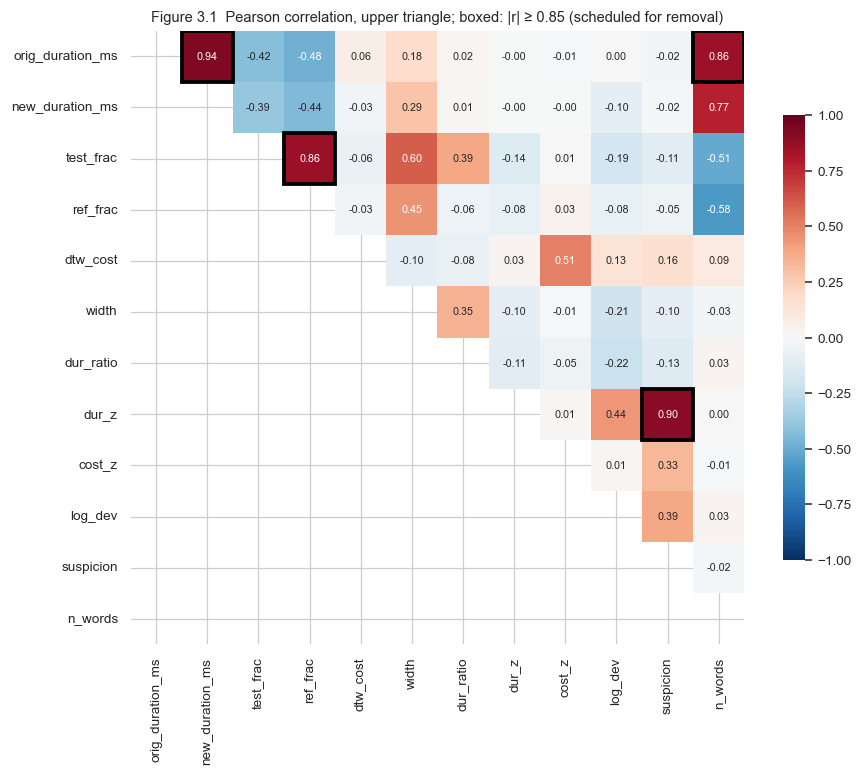

[('orig_duration_ms', 'new_duration_ms', np.float64(0.937)),
 ('orig_duration_ms', 'n_words', np.float64(0.858)),
 ('test_frac', 'ref_frac', np.float64(0.86)),
 ('dur_z', 'suspicion', np.float64(0.902))]

In [8]:
# the 12 numeric features that enter the collinearity screen
candidates = ["orig_duration_ms", "new_duration_ms", "test_frac", "ref_frac", "dtw_cost",
              "width", "dur_ratio", "dur_z", "cost_z", "log_dev", "suspicion", "n_words"]
corr = train[candidates].corr("pearson")
# hide the lower triangle, since it repeats the upper one
lower_triangle = np.tril(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, mask=lower_triangle, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7}, ax=ax)

# box every pair at |r| >= 0.85
flagged = []
for i in range(len(candidates)):
    for j in range(i + 1, len(candidates)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.85:
            box = plt.Rectangle((j, i), 1, 1, fill=False, ec="black", lw=2.5)
            ax.add_patch(box)
            flagged.append((candidates[i], candidates[j], round(r, 3)))

ax.set_title("Figure 3.1  Pearson correlation, upper triangle; boxed: |r| ≥ 0.85 "
             "(scheduled for removal)")
save(fig, "fig3_1_correlation_matrix")
flagged

## Figure 3.2: Collinear feature pair scatterplots

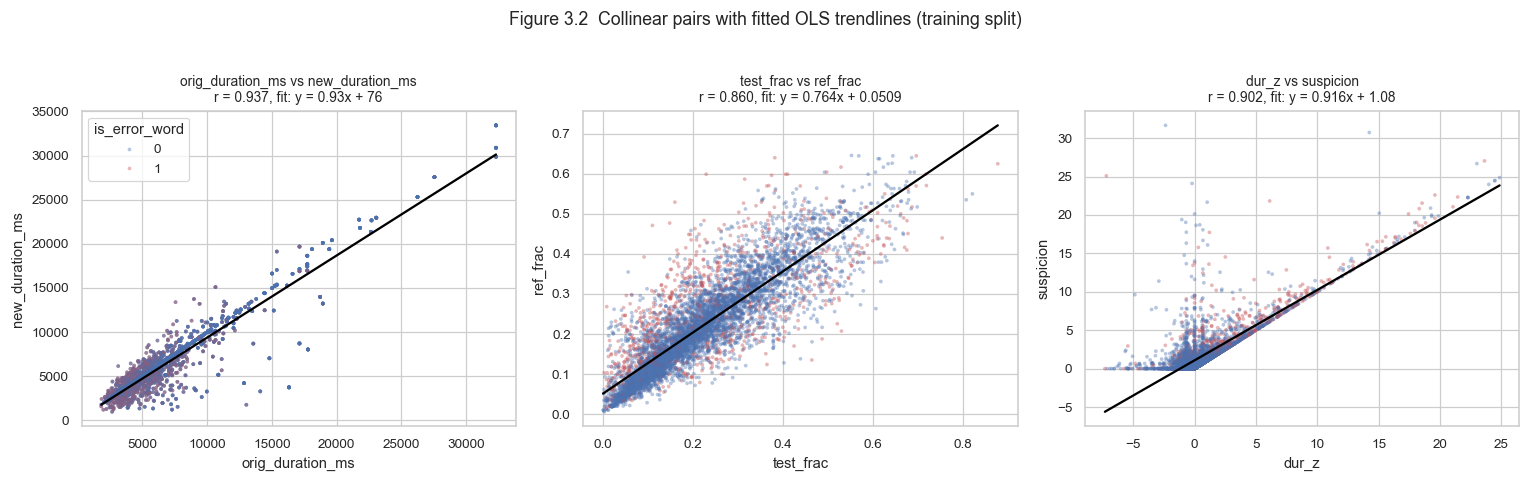

In [9]:
# the three collinear pairs found in Phase 1
pairs = [("orig_duration_ms", "new_duration_ms"),
         ("test_frac", "ref_frac"),
         ("dur_z", "suspicion")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (x_name, y_name) in zip(axes, pairs):
    pair_data = train[[x_name, y_name, pb.TARGET]]

    # trim dur_z's extreme tail for display only; the fit uses all rows
    if x_name == "dur_z":
        low = pair_data[x_name].quantile(0.005)
        high = pair_data[x_name].quantile(0.995)
        in_view = pair_data[x_name].between(low, high)
        shown = pair_data[in_view]
    else:
        shown = pair_data

    show_legend = x_name == "orig_duration_ms"
    sns.scatterplot(data=shown, x=x_name, y=y_name, hue=pb.TARGET,
                    palette=["#4c72b0", "#c44e52"], s=6, alpha=0.4, linewidth=0,
                    ax=ax, legend=show_legend)

    # ordinary least-squares line through all rows of the pair
    fit = stats.linregress(pair_data[x_name], pair_data[y_name])
    line_x = np.linspace(shown[x_name].min(), shown[x_name].max(), 100)
    line_y = fit.intercept + fit.slope * line_x
    ax.plot(line_x, line_y, color="black", lw=1.5)
    ax.set_title(f"{x_name} vs {y_name}\nr = {fit.rvalue:.3f}, "
                 f"fit: y = {fit.slope:.3g}x + {fit.intercept:.3g}", fontsize=9)

fig.suptitle("Figure 3.2  Collinear pairs with fitted OLS trendlines (training split)", y=1.03)
fig.tight_layout()
save(fig, "fig3_2_collinear_scatterplots")

### VIF before and after the planned drops (training split)

In [10]:
# VIF on the 12 candidates, then on the 9 retained features
vif_before = compute_vif(train[candidates])
train_engineered = add_engineered_features(train)
vif_after = compute_vif(train_engineered[pb.NUMERIC_FEATURES])

vif_table = pd.DataFrame({"VIF before (12 numeric)": vif_before,
                          "VIF after (9 retained)": vif_after})
# keep the rows in the same order as the candidate list
row_order = candidates + ["rec_len_ratio"]
vif_table = vif_table.loc[row_order]
vif_table.round(2)

,VIF before (12 numeric),VIF after (9 retained)
orig_duration_ms,14.71,NaN
new_duration_ms,13.01,NaN
test_frac,16.82,NaN
ref_frac,13.09,2.55
dtw_cost,1.54,1.50
width,3.38,2.21
dur_ratio,3.97,1.40
dur_z,11.15,NaN
cost_z,2.79,1.56
log_dev,1.46,1.38


## Figure 3.3: Feature-to-target importance (mutual information, training split)

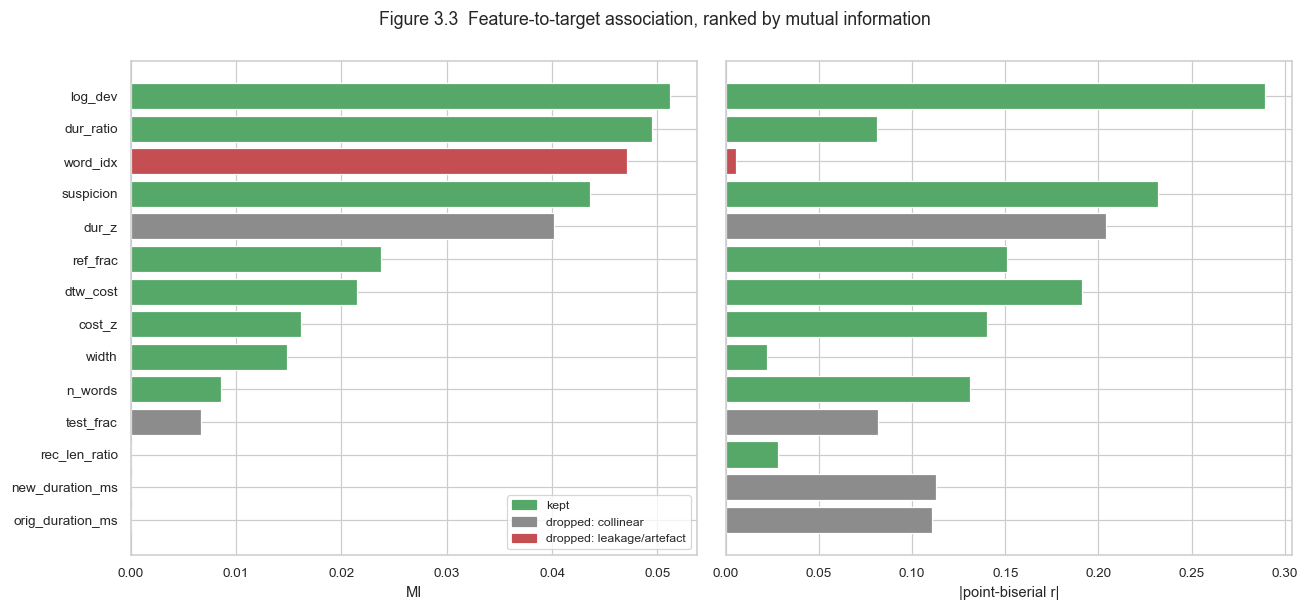

,MI,|point-biserial r|
log_dev,0.0512,0.2895
dur_ratio,0.0495,0.0811
word_idx,0.0471,0.0053
suspicion,0.0436,0.2317
dur_z,0.0402,0.2043
ref_frac,0.0238,0.1510
dtw_cost,0.0215,0.1910
cost_z,0.0162,0.1404
width,0.0148,0.0222
n_words,0.0086,0.1310


In [11]:
# include word_idx and rec_len_ratio to show why they were judged as they were
ranked_features = candidates + ["rec_len_ratio", "word_idx"]
feature_values = train_engineered[ranked_features]

# random_state fixes the nearest-neighbour estimate, so MI is repeatable
mi_scores = mutual_info_classif(feature_values, y_train, random_state=0)
mi = pd.Series(mi_scores, index=ranked_features)

abs_r = {}
for feature in ranked_features:
    r, _ = stats.pointbiserialr(y_train, train_engineered[feature])
    abs_r[feature] = abs(r)
abs_r = pd.Series(abs_r)

importance = pd.DataFrame({"MI": mi, "|point-biserial r|": abs_r})
importance = importance.sort_values("MI")

# colour each bar by what Phase 1 decided for that feature
def drop_status(feature):
    if feature in pb.NUMERIC_FEATURES:
        return "kept"
    if feature in pb.LEAKAGE:
        return "dropped: leakage/artefact"
    return "dropped: collinear"

status_colors = {"kept": "#55a868",
                 "dropped: collinear": "#8c8c8c",
                 "dropped: leakage/artefact": "#c44e52"}
bar_colors = []
for feature in importance.index:
    bar_colors.append(status_colors[drop_status(feature)])

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, score_name in zip(axes, importance.columns):
    ax.barh(importance.index, importance[score_name], color=bar_colors)
    ax.set_xlabel(score_name)

legend_patches = []
for color in status_colors.values():
    legend_patches.append(plt.Rectangle((0, 0), 1, 1, color=color))
axes[0].legend(handles=legend_patches, labels=list(status_colors), loc="lower right", fontsize=8)

fig.suptitle("Figure 3.3  Feature-to-target association, ranked by mutual information", y=1.0)
fig.tight_layout()
save(fig, "fig3_3_target_importance")
importance.sort_values("MI", ascending=False).round(4)

## Figure 4.1: Transformation stages (Raw → Log → Min-Max → Standardized)

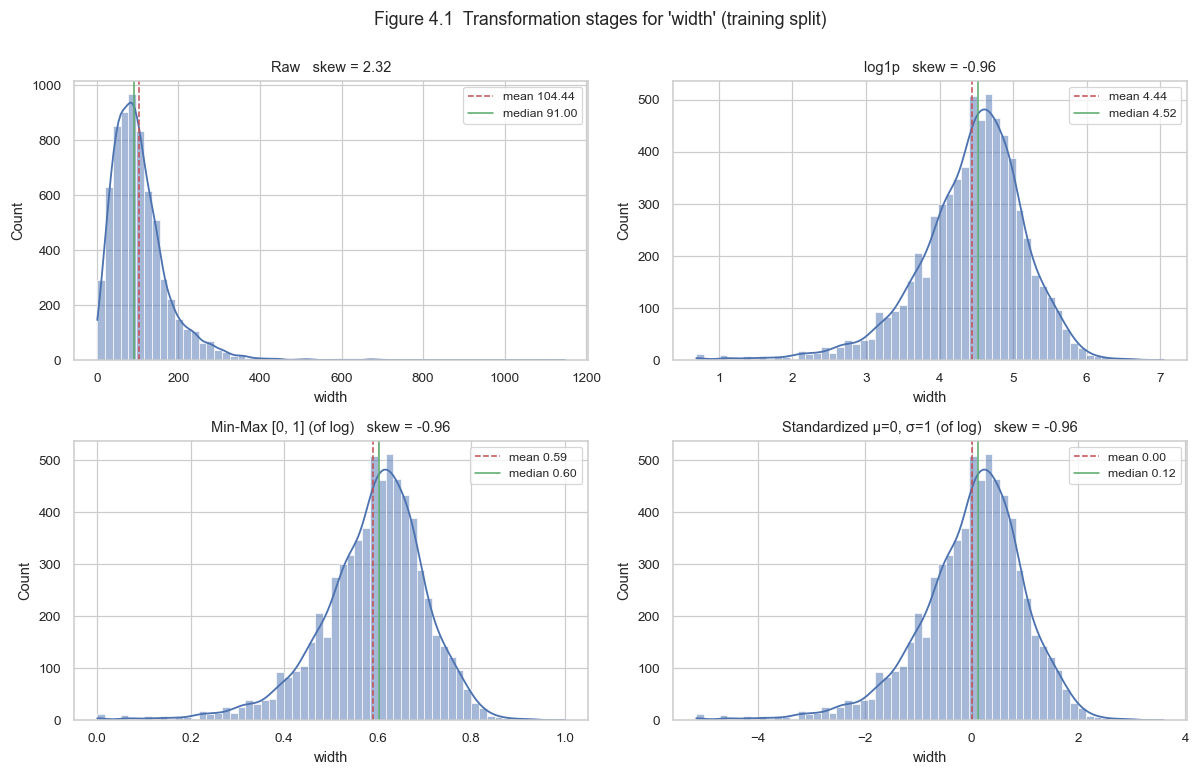

In [12]:
# one skewed feature, shown at each transformation stage
feature = "width"
raw = X_train[feature]
logged = np.log1p(raw)
# the scalers expect a 2-D table
logged_column = logged.to_frame()
min_maxed = MinMaxScaler().fit_transform(logged_column).ravel()
standardized = StandardScaler().fit_transform(logged_column).ravel()

stages = [("Raw", raw),
          ("log1p", logged),
          ("Min-Max [0, 1] (of log)", min_maxed),
          ("Standardized μ=0, σ=1 (of log)", standardized)]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (stage_name, values) in zip(axes.ravel(), stages):
    mean = np.mean(values)
    median = np.median(values)
    skew = stats.skew(values)
    sns.histplot(values, bins=60, kde=True, ax=ax, color="#4c72b0")
    ax.axvline(mean, color="#c44e52", ls="--", lw=1, label=f"mean {mean:.2f}")
    ax.axvline(median, color="#55a868", ls="-", lw=1, label=f"median {median:.2f}")
    ax.set_title(f"{stage_name}   skew = {skew:.2f}")
    ax.set_xlabel(feature)
    ax.legend(fontsize=8)

fig.suptitle(f"Figure 4.1  Transformation stages for '{feature}' (training split)", y=1.0)
fig.tight_layout()
save(fig, "fig4_1_transformation_grid")

## Figure 5.1: PCA scree and cumulative variance (fit on transformed `X_train`)

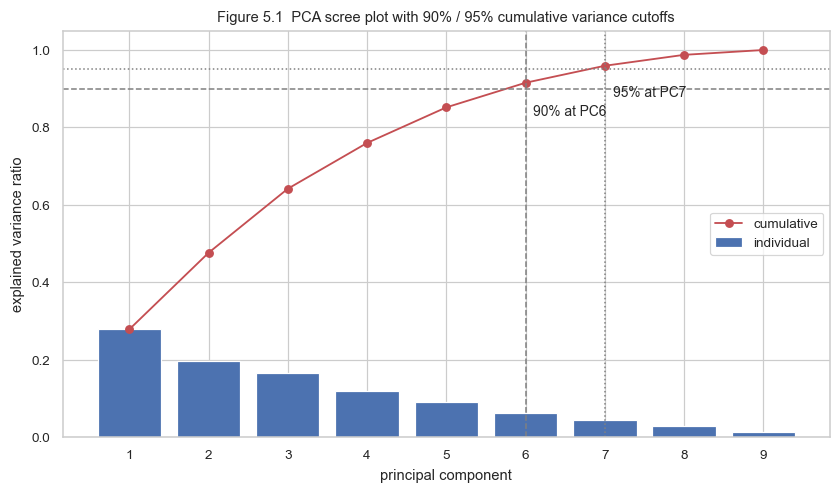

90% variance: 6 of 9 components; 95%: 7 of 9


PC1    0.278
PC2    0.476
PC3    0.642
PC4    0.760
PC5    0.852
PC6    0.915
PC7    0.959
PC8    0.988
PC9    1.000
dtype: float64

In [13]:
# PCA on the transformed training features
pca = PCA().fit(Xt_train)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_components = len(explained)
component_numbers = np.arange(1, n_components + 1)

# argmax returns the first component where the cumulative share reaches the cutoff
first_index_at_90 = np.argmax(cumulative >= 0.90)
first_index_at_95 = np.argmax(cumulative >= 0.95)
k90 = int(first_index_at_90) + 1
k95 = int(first_index_at_95) + 1

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(component_numbers, explained, color="#4c72b0", label="individual")
ax.plot(component_numbers, cumulative, "o-", color="#c44e52", label="cumulative")
for threshold, k, line_style in [(0.90, k90, "--"), (0.95, k95, ":")]:
    ax.axhline(threshold, color="gray", ls=line_style, lw=1)
    ax.axvline(k, color="gray", ls=line_style, lw=1)
    ax.text(k + 0.1, threshold - 0.07, f"{int(threshold * 100)}% at PC{k}", fontsize=9)
ax.set_xticks(component_numbers)
ax.set_xlabel("principal component")
ax.set_ylabel("explained variance ratio")
ax.set_ylim(0, 1.05)
ax.legend(loc="center right")
ax.set_title("Figure 5.1  PCA scree plot with 90% / 95% cumulative variance cutoffs")
save(fig, "fig5_1_pca_scree_plot")

print(f"90% variance: {k90} of {n_components} components; 95%: {k95} of {n_components}")
component_names = [f"PC{n}" for n in component_numbers]
pd.Series(cumulative, index=component_names).round(3)

## 4. Leave-one-reciter-out cross-validation (train side only)

Every fold refits the imputer, IQR fences and scaler on its own training
reciters, so the held-out reciter never shapes its own preprocessing.
All model and hyperparameter choices below use these out-of-fold scores only.
The two test reciters are not touched until Section 5.

Candidates follow the Phase 1 review: regularized logistic regression, random
forest, extra trees, histogram gradient boosting and LightGBM, each with and
without lag/lead features (`dtw_cost` and `dur_ratio` of the previous and next
word in the same recording). The primary metric is PR-AUC, with Macro F1 reported
alongside because of the 5.49 : 1 class imbalance.

In [14]:
# PR-AUC is the main metric because of the class imbalance; Macro F1 is the second
scoring = {"pr_auc": "average_precision",
           "roc_auc": "roc_auc",
           "f1": "f1",
           "f1_macro": "f1_macro",
           "precision": "precision",
           "recall": "recall"}

# the settings compared in cross-validation; "+ nbr" adds the lag/lead features
base_models = {
    "logreg (C=1)": dict(model="logreg", C=1.0),
    "logreg (C=0.1)": dict(model="logreg", C=0.1),
    "logreg, 1.5×IQR cap": dict(model="logreg", cap_k=1.5),
    "hist grad boosting": dict(model="hgb"),
    "random forest (leaf 5)": dict(model="rf", leaf=5),
    "random forest (leaf 20)": dict(model="rf", leaf=20),
    "extra trees (leaf 5)": dict(model="et", leaf=5),
    "extra trees (leaf 20)": dict(model="et", leaf=20),
    "lightgbm (leaf 5)": dict(model="lgbm", leaf=5),
    "lightgbm (leaf 20)": dict(model="lgbm", leaf=20),
}
candidate_models = {}
for name, settings in base_models.items():
    candidate_models[name] = settings
    candidate_models[name + " + nbr"] = dict(settings, neighbors=True)

# each fold holds out one training reciter
cv = LeaveOneGroupOut()


def run_cv(candidates):
    results = {}
    for name, settings in candidates.items():
        pipeline = pb.build_model_pipeline(**settings)
        # the whole pipeline is refit in every fold, so no fold sees its own validation data
        fold_scores = cross_validate(pipeline, X_train, y_train, groups=g_train,
                                     cv=cv, scoring=scoring)
        row = {}
        for metric in scoring:
            row[metric] = fold_scores[f"test_{metric}"].mean()
        row["pr_auc_std"] = fold_scores["test_pr_auc"].std()
        results[name] = row
    return pd.DataFrame(results).T


cv_table = run_cv(candidate_models)
print(f"chance PR-AUC = positive rate = {y_train.mean():.3f}")
cv_table.sort_values("pr_auc", ascending=False).round(3)

chance PR-AUC = positive rate = 0.149


,pr_auc,roc_auc,f1,f1_macro,precision,recall,pr_auc_std
hist grad boosting + nbr,0.757,0.920,0.681,0.812,0.664,0.701,0.029
lightgbm (leaf 20) + nbr,0.748,0.920,0.662,0.795,0.588,0.761,0.020
lightgbm (leaf 5) + nbr,0.745,0.918,0.664,0.797,0.591,0.761,0.026
random forest (leaf 5) + nbr,0.743,0.911,0.664,0.804,0.706,0.628,0.020
random forest (leaf 20) + nbr,0.714,0.902,0.626,0.772,0.543,0.742,0.021
lightgbm (leaf 20),0.707,0.905,0.627,0.774,0.545,0.742,0.019
lightgbm (leaf 5),0.706,0.905,0.623,0.771,0.547,0.727,0.019
hist grad boosting,0.705,0.903,0.638,0.785,0.604,0.679,0.020
extra trees (leaf 5) + nbr,0.699,0.894,0.609,0.762,0.526,0.726,0.029
random forest (leaf 5),0.698,0.898,0.636,0.787,0.655,0.620,0.017


### Ablations (out-of-fold, same protocol)

Three questions Phase 1 left open, each answered with the best tree model from the
table above: does lag/lead context help, does putting `word_idx` back help (it was
dropped because the first word is never an error), and does `rec_len_ratio` earn its place.

In [15]:
tree_rows = [n for n in cv_table.index if not n.startswith("logreg")]
best_tree = cv_table.loc[tree_rows, "pr_auc"].idxmax()
print("best tree candidate:", best_tree)
best_base = candidate_models[best_tree]

ablations = {
    "best, as selected": best_base,
    "best + word_idx": dict(best_base, add_features=["word_idx"]),
    "best, no rec_len_ratio": dict(best_base, remove_features=["rec_len_ratio"]),
    "best, no lag/lead": {k: v for k, v in best_base.items() if k != "neighbors"},
}
ablation_table = run_cv(ablations)
ablation_table.round(3)

best tree candidate: hist grad boosting + nbr


,pr_auc,roc_auc,f1,f1_macro,precision,recall,pr_auc_std
"best, as selected",0.757,0.920,0.681,0.812,0.664,0.701,0.029
best + word_idx,0.773,0.934,0.698,0.821,0.676,0.724,0.029
"best, no rec_len_ratio",0.595,0.856,0.582,0.751,0.549,0.622,0.029
"best, no lag/lead",0.705,0.903,0.638,0.785,0.604,0.679,0.020


### Two checks behind statements in the report

1. Does `C` reach the logistic regression? C = 1 and C = 0.1 give the same cross-validation
   scores to three decimals, so we compare the fitted coefficients directly.
2. `rec_len_ratio` on its own: point-biserial r and mutual information with the target on
   the training split (the Phase 2 report, section 3.3, quotes both).

In [16]:
# fit both settings on all training reciters and compare the coefficients
coefficients = {}
for C in (1.0, 0.1):
    fitted = pb.build_model_pipeline("logreg", C=C).fit(X_train, y_train)
    classifier = fitted.named_steps["model"]
    # the preprocessor outputs the columns in the order of NUMERIC_FEATURES
    coefficients[f"C={C}"] = pd.Series(classifier.coef_[0], index=pb.NUMERIC_FEATURES)
    assert classifier.C == C
coefficient_table = pd.DataFrame(coefficients)
coefficient_table["difference"] = coefficient_table["C=1.0"] - coefficient_table["C=0.1"]
print(coefficient_table.round(4).to_string())

# rec_len_ratio alone: linear (point-biserial) and non-linear (mutual information) association
rec_len_ratio = add_engineered_features(X_train)["rec_len_ratio"]
r, _ = stats.pointbiserialr(y_train, rec_len_ratio)
mi = mutual_info_classif(rec_len_ratio.to_frame(), y_train, random_state=0)[0]
print(f"\nrec_len_ratio on the training split: r = {r:.3f}, MI = {mi:.3f}")

                C=1.0   C=0.1  difference
ref_frac       0.4274  0.4236      0.0038
dtw_cost       0.5555  0.5455      0.0101
width          0.0450  0.0458     -0.0007
dur_ratio      0.0599  0.0577      0.0022
cost_z        -0.0562 -0.0487     -0.0075
log_dev        0.7196  0.7135      0.0061
suspicion      0.5185  0.5132      0.0053
n_words       -0.4301 -0.4250     -0.0051
rec_len_ratio  0.1131  0.1102      0.0029

rec_len_ratio on the training split: r = -0.028, MI = 0.000


## 5. Final fit on all training reciters, single evaluation on the held-out reciters

In [17]:
# pick the model with the best mean cross-validation PR-AUC
best_name = cv_table["pr_auc"].idxmax()
print("selected by CV PR-AUC:", best_name)

best_settings = candidate_models[best_name]

# the decision threshold is also chosen out-of-fold: the grid point that maximizes Macro F1
oof_prob = cross_val_predict(pb.build_model_pipeline(**best_settings), X_train, y_train,
                             groups=g_train, cv=cv, method="predict_proba")[:, 1]
grid = np.linspace(0.05, 0.95, 91)
oof_macro = [f1_score(y_train, (oof_prob >= t).astype(int), average="macro") for t in grid]
threshold = grid[int(np.argmax(oof_macro))]
print(f"threshold {threshold:.2f} (out-of-fold Macro F1 {max(oof_macro):.3f})")

final = pb.build_model_pipeline(**best_settings)
# refit on all 6 training reciters, then score the test reciters once
final.fit(X_train, y_train)

p_error = final.predict_proba(X_test)[:, 1]
y_pred = (p_error >= threshold).astype(int)

test_metrics = pd.Series({
    "PR-AUC": average_precision_score(y_test, p_error),
    "ROC-AUC": roc_auc_score(y_test, p_error),
    "Macro F1": f1_score(y_test, y_pred, average="macro"),
    "F1 (errors)": f1_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "chance PR-AUC": y_test.mean(),
})
test_metrics.round(3)

selected by CV PR-AUC: hist grad boosting + nbr


threshold 0.60 (out-of-fold Macro F1 0.820)


PR-AUC           0.780
ROC-AUC          0.924
Macro F1         0.829
F1 (errors)      0.712
precision        0.759
recall           0.670
chance PR-AUC    0.168
dtype: float64

## 6. Pipeline output verification and processed data

In [18]:
# checks on the final output; any failure stops the notebook
n_features_out = len(pb.NUMERIC_FEATURES)
assert Xt_train.shape[1] == n_features_out
assert Xt_test.shape[1] == n_features_out

n_missing_train = Xt_train.isna().sum().sum()
n_missing_test = Xt_test.isna().sum().sum()
assert n_missing_train == 0
assert n_missing_test == 0

# after StandardScaler, every training feature has mean 0 and std 1
train_means = Xt_train.mean()
train_stds = Xt_train.std(ddof=0)
assert np.allclose(train_means, 0, atol=1e-9)
assert np.allclose(train_stds, 1, atol=1e-6)

# no rows were deleted
n_rows_out = len(Xt_train) + len(Xt_test)
assert n_rows_out == len(df)

# save the processed data with the target and reciter attached
out_train = Xt_train.copy()
out_train[pb.TARGET] = y_train.values
out_train["reciter"] = g_train.values
out_train.to_csv(PROC / "train_processed.csv", index=False)

out_test = Xt_test.copy()
out_test[pb.TARGET] = y_test.values
out_test["reciter"] = test["reciter"].values
out_test.to_csv(PROC / "test_processed.csv", index=False)

verification = {
    "raw shape (N x P+1)": list(df.shape),
    "features in -> out": [df.shape[1] - 1, Xt_train.shape[1]],
    "rows in -> out": [len(df), n_rows_out],
    "train shape": list(Xt_train.shape),
    "test shape": list(Xt_test.shape),
    "missing after pipeline": int(n_missing_train + n_missing_test),
    "train means ~0, std ~1": bool(np.allclose(train_means, 0, atol=1e-9) and np.allclose(train_stds, 1, atol=1e-6)),
    "PCA components for 95% variance": f"{k95} of {n_components}",
}
verification_text = json.dumps(verification, indent=2)
(PROC / "verification.json").write_text(verification_text)
verification

{'raw shape (N x P+1)': [9086, 23],
 'features in -> out': [22, 9],
 'rows in -> out': [9086, 9086],
 'train shape': [6763, 9],
 'test shape': [2323, 9],
 'missing after pipeline': 0,
 'train means ~0, std ~1': True,
 'PCA components for 95% variance': '7 of 9'}